# Formative 2 · Task 1: Data Merge

**Multimodal Data Preprocessing: User Identity and Product Recommendation System**

The product recommendation model predicts **which product category a customer will buy** when they visit our social media pages. No single dataset holds everything it needs:

| Dataset | One row is | What it adds |
|---|---|---|
| `customer_social_profiles.csv` | one customer on one social platform | how engaged the customer is, how interested in buying, how they review |
| `customer_transactions.csv` | one purchase | what was bought (the **target**), how much, when, and the rating |

This notebook explores both files, cleans them, explains and validates the join, and engineers the features. The output is `data/processed/merged_customer_dataset.csv`, the input to the product model in Task 4.

## 0. Setup

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

social_raw = pd.read_csv("data/raw/customer_social_profiles.csv")
trans_raw = pd.read_csv("data/raw/customer_transactions.csv")

print("social profiles:", social_raw.shape)
print("transactions:", trans_raw.shape)

social profiles: (155, 5)
transactions: (150, 6)


## 1. First look

### 1.1 Variable types and summary statistics

In [2]:
social_raw.info()
social_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    str    
 1   social_media_platform    155 non-null    str    
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 6.2 KB


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [3]:
trans_raw.info()
trans_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    str    
 4   product_category    150 non-null    str    
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 7.2 KB


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


| Column | Dataset | Variable type |
|---|---|---|
| `customer_id_new` | social | identifier (text, e.g. `A123`) |
| `social_media_platform` | social | categorical, nominal |
| `engagement_score` | social | numeric, discrete score |
| `purchase_interest_score` | social | numeric, continuous score |
| `review_sentiment` | social | categorical, ordinal (Negative < Neutral < Positive) |
| `customer_id_legacy` | transactions | identifier (integer) |
| `transaction_id` | transactions | identifier (integer) |
| `purchase_amount` | transactions | numeric, continuous (money) |
| `purchase_date` | transactions | date (read as text, converted in section 3) |
| `product_category` | transactions | categorical, nominal: the **target** |
| `customer_rating` | transactions | numeric, continuous rating |

In [4]:
numeric = pd.concat([social_raw[["engagement_score", "purchase_interest_score"]],
                     trans_raw[["purchase_amount", "customer_rating"]]], axis=1)
summary = numeric.describe().T
summary["skew"] = numeric.skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
engagement_score,155.0,75.61,14.57,50.0,63.50,77.0,87.5,99.0,-0.11
purchase_interest_score,155.0,3.15,1.14,1.0,2.35,3.2,4.1,5.0,-0.23
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.0,388.5,495.0,0.06
customer_rating,140.0,2.98,1.21,1.0,1.95,3.0,4.0,5.0,-0.08


In [5]:
for col in ["social_media_platform", "review_sentiment"]:
    print(social_raw[col].value_counts(), "\n")
print(trans_raw["product_category"].value_counts(normalize=True).round(3) * 100)

social_media_platform
Twitter      38
LinkedIn     32
TikTok       32
Facebook     27
Instagram    26
Name: count, dtype: int64 

review_sentiment
Positive    63
Neutral     50
Negative    42
Name: count, dtype: int64 

product_category
Sports         23.3
Electronics    22.7
Clothing       18.7
Groceries      18.7
Books          16.7
Name: proportion, dtype: float64


**What the summaries show.**
- The variables sit on very different scales: engagement 50–99, purchase interest 1.0–5.0, purchase amount 51–495, rating 1.0–5.0. Distance- or gradient-based models (logistic regression) need scaling; tree models don't.
- All four numeric columns are close to symmetric (|skew| ≤ 0.23), so none needs a log or power transform.
- The target is fairly balanced: 5 product categories, from 16.7% (Books) to 23.3% (Sports) of transactions.
- Twitter is the most common platform (24.5%), and review sentiment leans positive (40.6% positive, 27.1% negative).

### 1.2 Data quality: missing values, duplicates, keys

In [6]:
print("Missing values in the social file:")
print(social_raw.isnull().sum(), "\n")
print("Missing values in the transactions file:")
print(trans_raw.isnull().sum(), "\n")

print("Exact duplicate rows - social:", social_raw.duplicated().sum(),
      "| transactions:", trans_raw.duplicated().sum())
print("Duplicate transaction_id:", trans_raw["transaction_id"].duplicated().sum())
print("Customers - social:", social_raw["customer_id_new"].nunique(),
      "| transactions:", trans_raw["customer_id_legacy"].nunique())
print("Most rows for one customer - social:", social_raw["customer_id_new"].value_counts().max(),
      "| transactions:", trans_raw["customer_id_legacy"].value_counts().max())
print("ID examples:", social_raw["customer_id_new"].head(3).tolist(), "vs",
      trans_raw["customer_id_legacy"].head(3).tolist())

Missing values in the social file:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64 

Missing values in the transactions file:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64 

Exact duplicate rows - social: 5 | transactions: 0
Duplicate transaction_id: 0
Customers - social: 84 | transactions: 75
Most rows for one customer - social: 7 | transactions: 6
ID examples: ['A178', 'A190', 'A150'] vs [151, 192, 114]


**Data-quality findings.**
- `customer_rating` is the only column with gaps: 10 of 150 transactions (6.7%), spread across all five categories.
- The social file has **5 exact duplicate rows**: its last five rows repeat earlier rows word for word.
- **The customer keys don't match as written.** Customer `A178` in the social file is `178` in the transactions; both files use the range 100–199.
- Neither key is unique: a customer can have up to 7 social rows and up to 6 transactions. The join must handle that (section 4).

## 2. Exploratory data analysis

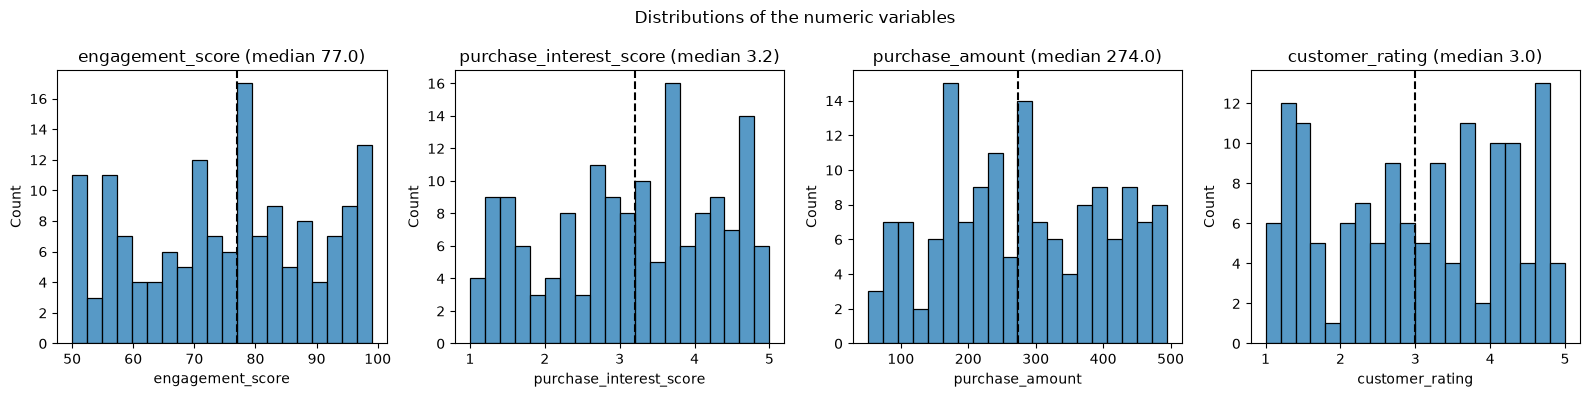

In [7]:
numeric_cols = {
    "engagement_score": social_raw["engagement_score"],
    "purchase_interest_score": social_raw["purchase_interest_score"],
    "purchase_amount": trans_raw["purchase_amount"],
    "customer_rating": trans_raw["customer_rating"].dropna(),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, values) in zip(axes, numeric_cols.items()):
    sns.histplot(values, bins=20, ax=ax)
    ax.axvline(values.median(), color="black", linestyle="--")
    ax.set_title(f"{name} (median {values.median()})")
plt.suptitle("Distributions of the numeric variables")
plt.tight_layout()
plt.savefig("figures/task1_01_distributions.png")
plt.show()

**Distributions.** None of the four variables is bell-shaped. Each spreads fairly evenly across its range, with the median near the middle (engagement 77, interest 3.2, amount 274, rating 3.0). No transform is needed, and the median is a safe value to fill the missing ratings.

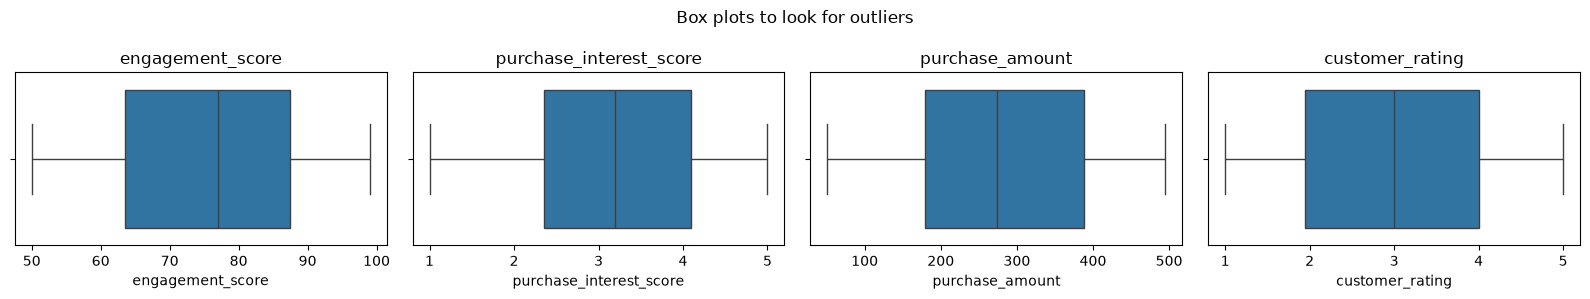

engagement_score: 0 outliers, values from 50 to 99
purchase_interest_score: 0 outliers, values from 1.0 to 5.0
purchase_amount: 0 outliers, values from 51 to 495
customer_rating: 0 outliers, values from 1.0 to 5.0


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (name, values) in zip(axes, numeric_cols.items()):
    sns.boxplot(x=values, ax=ax)
    ax.set_title(name)
plt.suptitle("Box plots to look for outliers")
plt.tight_layout()
plt.savefig("figures/task1_02_outliers.png")
plt.show()

# IQR rule: anything below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is an outlier
for name, values in numeric_cols.items():
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    outliers = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    print(f"{name}: {outliers} outliers, values from {values.min()} to {values.max()}")

**Outliers.** The 1.5 × IQR rule flags **no outliers** in any numeric column, and every value is inside its valid range (scores 50–99 and 1–5, amounts 51–495, ratings 1–5). Nothing needs removing or capping.

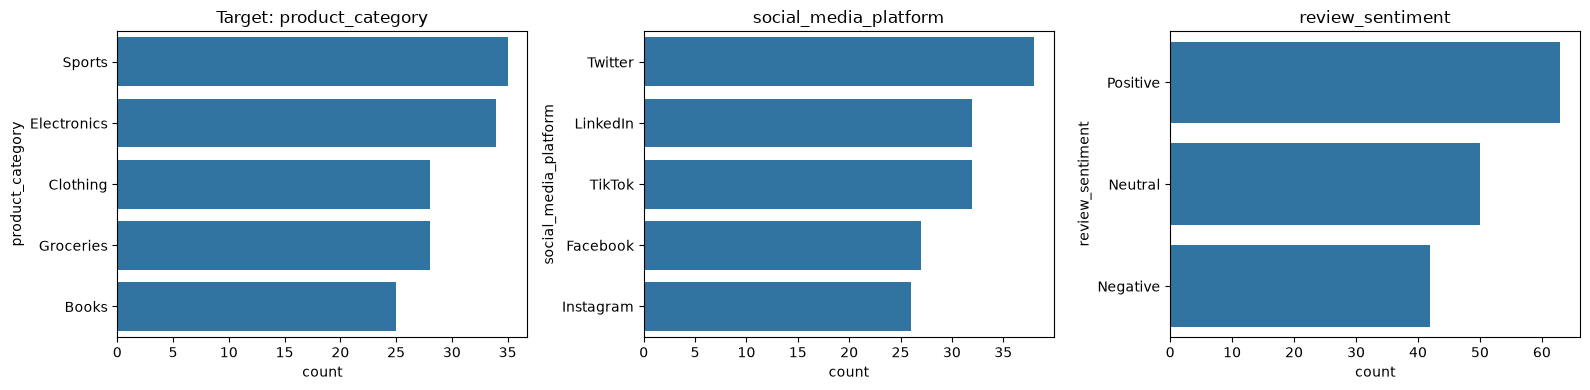

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(y=trans_raw["product_category"], order=trans_raw["product_category"].value_counts().index, ax=axes[0])
axes[0].set_title("Target: product_category")
sns.countplot(y=social_raw["social_media_platform"], order=social_raw["social_media_platform"].value_counts().index, ax=axes[1])
axes[1].set_title("social_media_platform")
sns.countplot(y=social_raw["review_sentiment"], order=social_raw["review_sentiment"].value_counts().index, ax=axes[2])
axes[2].set_title("review_sentiment")
plt.tight_layout()
plt.savefig("figures/task1_03_categories.png")
plt.show()

**Class balance.** No product category dominates (25 to 35 transactions each), so the product model needs no resampling or class weights. Accuracy is a fair headline metric, with macro F1 beside it. After the merge each class has only 20 to 28 rows, so cross-validation will give a steadier score than one train/test split.

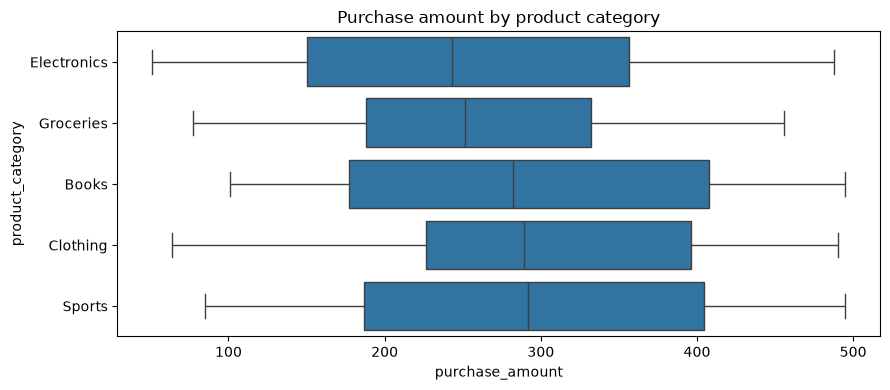

product_category
Electronics    243.0
Groceries      251.5
Books          282.0
Clothing       289.5
Sports         292.0
Name: purchase_amount, dtype: float64


In [10]:
order = trans_raw.groupby("product_category")["purchase_amount"].median().sort_values().index
plt.figure(figsize=(9, 4))
sns.boxplot(data=trans_raw, x="purchase_amount", y="product_category", order=order)
plt.title("Purchase amount by product category")
plt.tight_layout()
plt.savefig("figures/task1_04_amount_by_category.png")
plt.show()

print(trans_raw.groupby("product_category")["purchase_amount"].median().sort_values())

**Amount by category.** Median spend ranges only from 243 (Electronics) to 292 (Sports), and the boxes overlap heavily. Spend alone won't separate the products, so the model needs the social and timing features as well, which is the reason for the merge.

## 3. Cleaning

Rules, applied in this order:

1. **Exact duplicate rows** are dropped from both files: a repeated row is a copy, not a second event.
2. **Types**: `purchase_date` becomes a real date, and text categories are trimmed and title-cased so `"facebook "` and `"Facebook"` count as one platform.
3. **Customer key**: the two files name customers differently (`customer_id_new` is text like `A123`, `customer_id_legacy` is the integer `123`). Both are turned into one integer column, `customer_id`, by removing the letter `A`.
4. **Missing values**: the 10 missing `customer_rating` values get the median rating (3.0), plus a flag `rating_missing` so the model can still tell the value was filled in. Filling per product category would use the target to fill a feature, which leaks the answer, so it is not done.
5. **Repeated customer + platform rows that are not exact copies are kept.** 17 such pairs cover 36 rows; for example, `A178` appears on LinkedIn with engagement 74 and with 53. They read as separate observations of the same account, so section 4.2 averages them instead of picking one.
6. **No outlier treatment.** Section 2 found no outliers, so nothing is removed or capped.

In [11]:
social = social_raw.drop_duplicates().copy()
trans = trans_raw.drop_duplicates().copy()

# one customer key for both files: "A178" -> 178
social["customer_id"] = social["customer_id_new"].str.replace("A", "").astype(int)
trans["customer_id"] = trans["customer_id_legacy"]

# tidy the text columns and fix the date type
social["social_media_platform"] = social["social_media_platform"].str.strip().str.title()
social["review_sentiment"] = social["review_sentiment"].str.strip().str.title()
trans["product_category"] = trans["product_category"].str.strip().str.title()
trans["purchase_date"] = pd.to_datetime(trans["purchase_date"])

# fill the missing ratings with the median, and keep a flag for the filled ones
trans["rating_missing"] = trans["customer_rating"].isnull().astype(int)
trans["customer_rating"] = trans["customer_rating"].fillna(trans["customer_rating"].median())

print("social rows:", len(social_raw), "->", len(social))
print("transaction rows:", len(trans_raw), "->", len(trans))
print("missing values left:", social.isnull().sum().sum() + trans.isnull().sum().sum())
print("purchase_date type:", trans["purchase_date"].dtype)

social rows: 155 -> 150
transaction rows: 150 -> 150
missing values left: 0
purchase_date type: datetime64[us]


## 4. Merge

### 4.1 Which join, and why

Two facts decide the join:

* **Cardinality.** A customer appears on several social rows (one per platform) *and* in several transactions. Joining the raw files on `customer_id` is many-to-many: every transaction is copied once per social row. The model would then see copies of the same purchase, and customers with many platforms would count more. The cell below measures that blow-up.
* **The model's job.** It predicts what a customer *visiting our social media* will buy, so each training row needs both the purchase (target) and the customer's social behaviour (features).

So the social file is first **aggregated to one row per customer** (section 4.2), then joined to the transactions with an **inner, many-to-one join**: one row per transaction, each carrying its customer's social profile. Transactions from customers with no social profile are dropped, because their social features would be empty. The cell below counts them.

In [12]:
social_ids = set(social["customer_id"])
trans_ids = set(trans["customer_id"])

print("customers in both files:", len(social_ids & trans_ids))
print("only in transactions:", len(trans_ids - social_ids))
print("only in social profiles:", len(social_ids - trans_ids))
print("transactions with a social profile:", trans["customer_id"].isin(social_ids).sum())
print("rows if we joined the raw files:", len(trans.merge(social, on="customer_id")))

customers in both files: 61
only in transactions: 14
only in social profiles: 23
transactions with a social profile: 117
rows if we joined the raw files: 213


**Key overlap.** 61 customers appear in both files, 14 only in the transactions and 23 only in the social profiles. 117 of the 150 transactions belong to a customer with a social profile. Joining the raw files would turn those 117 transactions into **213 rows**: 96 copies that would make some purchases count two or three times.

### 4.2 One social profile per customer

In [13]:
social["sentiment_score"] = social["review_sentiment"].map({"Negative": -1, "Neutral": 0, "Positive": 1})

profile = social.groupby("customer_id").agg(
    social_rows=("social_media_platform", "count"),
    n_platforms=("social_media_platform", "nunique"),
    engagement_mean=("engagement_score", "mean"),
    engagement_max=("engagement_score", "max"),
    interest_mean=("purchase_interest_score", "mean"),
    interest_max=("purchase_interest_score", "max"),
    sentiment_mean=("sentiment_score", "mean"),
    positive_share=("sentiment_score", lambda s: (s == 1).mean()),
    negative_share=("sentiment_score", lambda s: (s == -1).mean()),
)

# 1 if the customer is on that platform, 0 if not
platforms = pd.crosstab(social["customer_id"], social["social_media_platform"]).clip(upper=1)
platforms.columns = ["on_" + name.lower() for name in platforms.columns]

profile = profile.join(platforms).reset_index()
print(len(social), "social rows ->", len(profile), "customer profiles")
profile.head()

150 social rows -> 84 customer profiles


,customer_id,social_rows,n_platforms,engagement_mean,engagement_max,interest_mean,interest_max,sentiment_mean,positive_share,negative_share,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter
0,100,2,2,77.000000,81,4.400000,4.4,-0.500000,0.000000,0.500000,0,1,0,0,1
1,101,1,1,68.000000,68,1.000000,1.0,0.000000,0.000000,0.000000,0,0,0,0,1
2,102,1,1,51.000000,51,4.800000,4.8,0.000000,0.000000,0.000000,0,0,1,0,0
3,103,3,2,64.333333,77,2.866667,3.6,0.333333,0.666667,0.333333,1,1,0,0,0
4,104,3,2,83.000000,91,2.933333,4.6,-0.666667,0.000000,0.666667,1,0,0,0,1


### 4.3 Join and post-merge checks

In [14]:
merged = trans.merge(profile, on="customer_id", how="inner", validate="many_to_one")

print("merged shape:", merged.shape)
print("transactions dropped (no social profile):", len(trans) - len(merged))
print("one row per transaction:", merged["transaction_id"].is_unique)
print("same count as transactions with a profile:", len(merged) == trans["customer_id"].isin(social_ids).sum())
print("missing values after the merge:", merged.isnull().sum().sum())

merged shape: (117, 22)
transactions dropped (no social profile): 33
one row per transaction: True
same count as transactions with a profile: True
missing values after the merge: 0


In [15]:
# did the inner join change the class balance of the target?
balance = pd.DataFrame({
    "before merge %": trans["product_category"].value_counts(normalize=True) * 100,
    "after merge %": merged["product_category"].value_counts(normalize=True) * 100,
})
balance["change"] = balance["after merge %"] - balance["before merge %"]
balance.round(1)

,before merge %,after merge %,change
product_category,,,
Sports,23.3,23.9,0.6
Electronics,22.7,23.1,0.4
Clothing,18.7,18.8,0.1
Groceries,18.7,17.1,-1.6
Books,16.7,17.1,0.4


**Post-merge checks.** All the checks pass. The merged table has 117 rows, one per transaction, covering 61 customers. Dropping the 33 transactions without a social profile moves each class's share by at most 1.6 percentage points (Groceries), so the inner join doesn't bias the target.

## 5. Feature engineering

| Feature | From | Why |
|---|---|---|
| `engagement_mean/max`, `interest_mean/max` | social | how active and how ready to buy the customer is |
| `sentiment_mean`, `positive_share`, `negative_share` | social | review mood, ordered −1 / 0 / +1 |
| `n_platforms`, `on_<platform>` | social | where the customer is reachable, and how widely |
| `engagement_x_interest` | social | engaged **and** interested customers are the likeliest buyers |
| `purchase_month`, `purchase_dayofweek`, `purchase_is_weekend` | transactions | seasonality and weekly buying patterns |
| `customer_txn_count`, `customer_avg_amount`, `amount_vs_customer_avg` | transactions | how often and how much the customer usually buys; whether this purchase is unusually large |
| `purchase_amount`, `customer_rating`, `rating_missing` | transactions | spend, satisfaction, and whether the rating was filled in |

None of these features uses `product_category`, so nothing leaks the target. The target is kept as text (`product_category`) and as an integer label (`product_label`).

In [16]:
merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_dayofweek"] = merged["purchase_date"].dt.day_of_week
merged["purchase_is_weekend"] = (merged["purchase_dayofweek"] >= 5).astype(int)

merged["customer_txn_count"] = merged.groupby("customer_id")["purchase_amount"].transform("count")
merged["customer_avg_amount"] = merged.groupby("customer_id")["purchase_amount"].transform("mean")
merged["amount_vs_customer_avg"] = merged["purchase_amount"] / merged["customer_avg_amount"]
merged["engagement_x_interest"] = merged["engagement_mean"] * merged["interest_mean"]

categories = sorted(merged["product_category"].unique())
labels = {category: i for i, category in enumerate(categories)}
merged["product_label"] = merged["product_category"].map(labels)
print(labels)

{'Books': 0, 'Clothing': 1, 'Electronics': 2, 'Groceries': 3, 'Sports': 4}


In [17]:
features = [
    "purchase_amount", "customer_rating", "rating_missing",
    "purchase_month", "purchase_dayofweek", "purchase_is_weekend",
    "customer_txn_count", "customer_avg_amount", "amount_vs_customer_avg",
    "social_rows", "n_platforms", "engagement_mean", "engagement_max", "interest_mean", "interest_max",
    "engagement_x_interest", "sentiment_mean", "positive_share", "negative_share",
    "on_facebook", "on_instagram", "on_linkedin", "on_tiktok", "on_twitter",
]
columns = ["transaction_id", "customer_id", "purchase_date", "product_category", "product_label"] + features
dataset = merged[columns].sort_values("transaction_id").reset_index(drop=True)
print(len(features), "features,", len(dataset), "rows")
dataset.head()

24 features, 117 rows


,transaction_id,customer_id,purchase_date,product_category,product_label,purchase_amount,customer_rating,rating_missing,purchase_month,purchase_dayofweek,...,interest_max,engagement_x_interest,sentiment_mean,positive_share,negative_share,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter
0,1001,151,2024-01-01,Sports,4,408,2.3,0,1,0,...,3.6,155.277778,-0.333333,0.000000,0.333333,0,0,0,1,1
1,1002,192,2024-01-02,Electronics,2,332,4.2,0,1,1,...,4.3,258.000000,1.000000,1.000000,0.000000,0,1,0,0,0
2,1003,114,2024-01-03,Electronics,2,442,2.1,0,1,2,...,4.8,417.600000,-1.000000,0.000000,1.000000,1,0,0,0,0
3,1005,160,2024-01-05,Clothing,1,64,1.3,0,1,4,...,2.9,181.666667,0.333333,0.333333,0.000000,0,1,1,1,0
4,1006,120,2024-01-06,Groceries,3,395,1.1,0,1,5,...,3.6,205.333333,1.000000,1.000000,0.000000,1,1,0,0,0


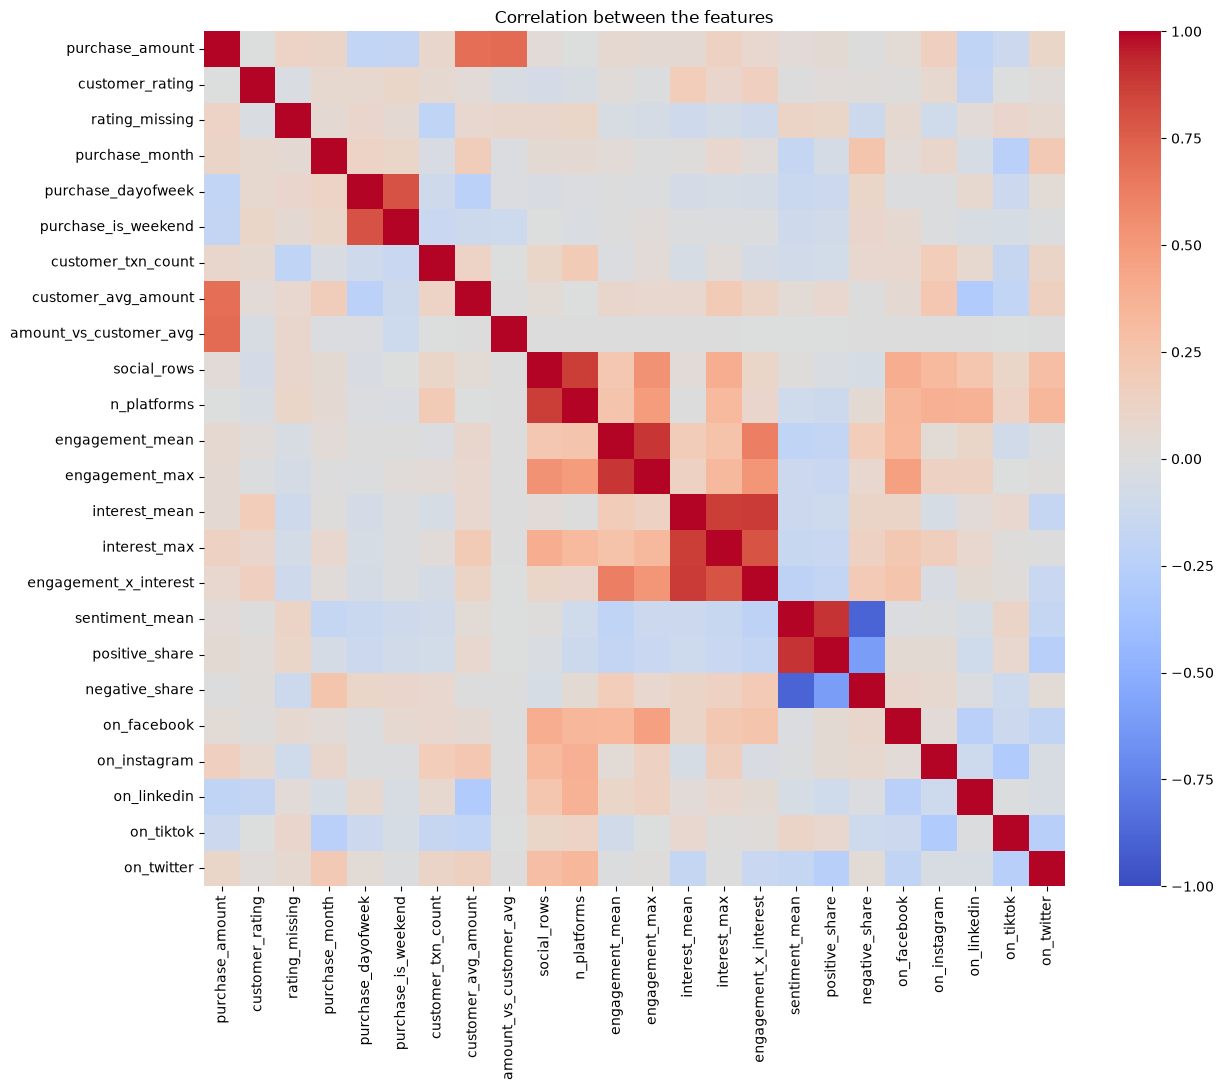

sentiment_mean      positive_share            0.906
engagement_mean     engagement_max            0.895
sentiment_mean      negative_share           -0.884
interest_mean       engagement_x_interest     0.877
social_rows         n_platforms               0.875
interest_mean       interest_max              0.874
purchase_dayofweek  purchase_is_weekend       0.798
interest_max        engagement_x_interest     0.795
purchase_amount     amount_vs_customer_avg    0.708
                    customer_avg_amount       0.692
dtype: float64

In [18]:
corr = dataset[features].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation between the features")
plt.tight_layout()
plt.savefig("figures/task1_05_feature_correlations.png")
plt.show()

# the 10 strongest pairs
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
upper.stack().sort_values(key=abs, ascending=False).head(10).round(3)

**Correlations.** The strongest pairs are features built from the same source, as expected:
- `sentiment_mean` vs `positive_share` (0.91) and vs `negative_share` (−0.88)
- `engagement_mean` vs `engagement_max` (0.89), and `interest_mean` vs `interest_max` (0.87)
- `social_rows` vs `n_platforms` (0.87), and `purchase_dayofweek` vs `purchase_is_weekend` (0.80)

Tree models (Random Forest, XGBoost) cope with such pairs. For logistic regression, keep one feature from each pair. No transaction feature correlates with any social feature above |r| = 0.29, so the two sources carry *different* information, which is what makes the merge worth doing. `amount_vs_customer_avg` is uncorrelated with every customer-level feature by construction: its average is exactly 1 for every customer.

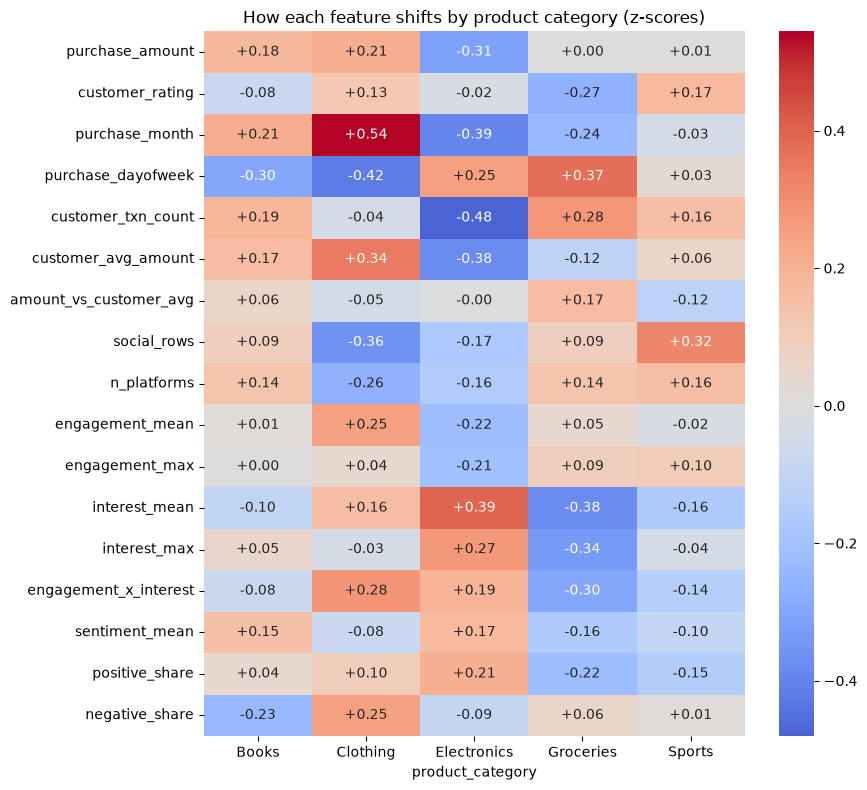

In [19]:
# which features shift between product categories? mean of each feature per category, as a z-score
numeric_features = [f for f in features if not f.startswith("on_") and dataset[f].nunique() > 2]
z = (dataset[numeric_features] - dataset[numeric_features].mean()) / dataset[numeric_features].std()
by_category = z.groupby(dataset["product_category"]).mean().T

plt.figure(figsize=(9, 8))
sns.heatmap(by_category, annot=True, fmt="+.2f", cmap="coolwarm", center=0)
plt.title("How each feature shifts by product category (z-scores)")
plt.tight_layout()
plt.savefig("figures/task1_06_features_by_category.png")
plt.show()

**Signal for the product model.** No category differs from the average by more than about half a standard deviation on any feature:
- Electronics buyers have the highest purchase interest (+0.39), the fewest transactions per customer (−0.48) and the smallest purchases (−0.31).
- Groceries buyers have the lowest purchase interest (−0.38).
- Clothing purchases fall later in the period (month +0.54), Electronics earlier (−0.39).

These shifts are real but small, and they rest on 117 rows. Expect the product model's accuracy to be modest, and report it against the 24% you get by always predicting the most common class (Sports). Any limit there comes from the data, not the pipeline.

## 6. Save and validate the merged dataset

In [20]:
dataset.to_csv("data/processed/merged_customer_dataset.csv", index=False)
with open("data/processed/product_label_map.json", "w") as f:
    json.dump(labels, f, indent=2)

check = pd.read_csv("data/processed/merged_customer_dataset.csv")
print("shape:", check.shape)
print("missing values:", check.isnull().sum().sum())
print("duplicate transaction_id:", check["transaction_id"].duplicated().sum())
print("target classes:", check["product_category"].nunique())

shape: (117, 29)
missing values: 0
duplicate transaction_id: 0
target classes: 5


## 7. Summary and hand-off

| Step | Result |
|---|---|
| Cleaning | 5 duplicate social rows dropped; 10 missing ratings filled with the median and flagged; dates parsed; customer keys unified (`A178` → `178`) |
| Join | social rows aggregated to 84 customer profiles, then an inner many-to-one join on `customer_id`: 117 transactions from 61 customers, no row duplicated, class balance within 1.6 points of the original |
| Features | 24: spend, rating, timing, customer purchase history, engagement, interest, sentiment and platform presence |
| Output | `data/processed/merged_customer_dataset.csv` (117 rows × 29 columns) and `data/processed/product_label_map.json` |

**For the product recommendation model (Task 4):** the target is `product_label` (names in `product_label_map.json`) and the inputs are the 24 feature columns. Drop `transaction_id`, `customer_id` and `purchase_date` before training. Use stratified 5-fold cross-validation, and report accuracy, macro F1 and log loss against the 24% majority-class baseline.